# 04 – Logistic regression

The simplest model: a weighted sum of the features, squeezed through a sigmoid into a probability.
It's the **interpretable** model in our ensemble: each feature gets one coefficient that we can read.

Preprocessing it needs (trees don't):
1. **No NaN allowed** → fill with the median, plus a 0/1 "was missing" column (missingness is informative!)
2. **Skewed counts** (`*_n_songs`, up to thousands) → `log1p`
3. **Same scale for all features** → `StandardScaler` (mean 0, std 1). Otherwise the regularization punishes features
   with small units more than features with large units.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from utils import load_features, compare_to_baseline, save_predictions

# same plot style as in the other notebooks
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#52514e"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": GREY, "xtick.color": GREY, "ytick.color": GREY,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "figure.dpi": 110,
})

# data + features from features.py (target encodings learned on dev only)
dev, valid, test, X_dev, X_valid, X_test = load_features()
y_dev, y_valid = dev["music_hit"], valid["music_hit"]
print("X_dev:", X_dev.shape, "| X_valid:", X_valid.shape, "| X_test:", X_test.shape)

X_dev: (280040, 191) | X_valid: (70011, 191) | X_test: (87513, 191)


## Preprocessing + model in one pipeline

In [2]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# step 2: log1p of the song-count columns (done by hand, it's one line)
count_cols = [c for c in X_dev.columns if c.endswith("_n_songs")]
def log_counts(X):
    X = X.copy()
    X[count_cols] = np.log1p(X[count_cols])
    return X

# steps 1 + 3 + the model, chained: fitted on dev only, then reused unchanged on valid/test
model = make_pipeline(
    SimpleImputer(strategy="median", add_indicator=True),  # NaN -> median, + 'missing' columns
    StandardScaler(),                                      # every column: mean 0, std 1
    LogisticRegression(max_iter=2000),                     # C=1.0 (default L2 regularization)
)
model.fit(log_counts(X_dev), y_dev)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('simpleimputer', ...), ('standardscaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](191,)","['audio_dance','audio_energy','audio_key',...,'album_name_te', 'genre_te_mean','genre_te_max']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,191
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estimatorto account for missingness despite imputation. If a feature has nomissing values at fit/train time, the feature won't appear onthe missing indicator even if there are missing values attransform/test time.",True
,"missing_values missing_values: int, float, str, np.nan, None o

## Validation AUC vs. baseline

In [3]:
# probability of 'hit' (column 1) for every validation song
valid_pred = model.predict_proba(log_counts(X_valid))[:, 1]
auc = compare_to_baseline("Logistic regression", y_valid, valid_pred)

Logistic regression: validation AUC = 0.9595
baseline (artist_followers alone)  = 0.8747
improvement                        = +0.0848


## What did the model learn?
Because all features are standardized, the coefficients are comparable:
a coefficient of +1 means "one standard deviation more of this feature raises the log-odds of a hit by 1".

largest positive coefficients (-> more hits):
log_followers          1.671
album_name_te          1.029
record_label_te        0.382
explicit               0.334
title_is_album_name    0.245
artist_name_te         0.194
audio_acoustic         0.090
genre_piano cover      0.071

largest negative coefficients (-> fewer hits):
artist_name_n_songs      -0.480
genre_karaoke            -0.358
audio_speech             -0.330
title_has_karaoke        -0.327
album_name_n_songs       -0.287
title_has_instrumental   -0.202
genre_pop                -0.171
genre_workout product    -0.145


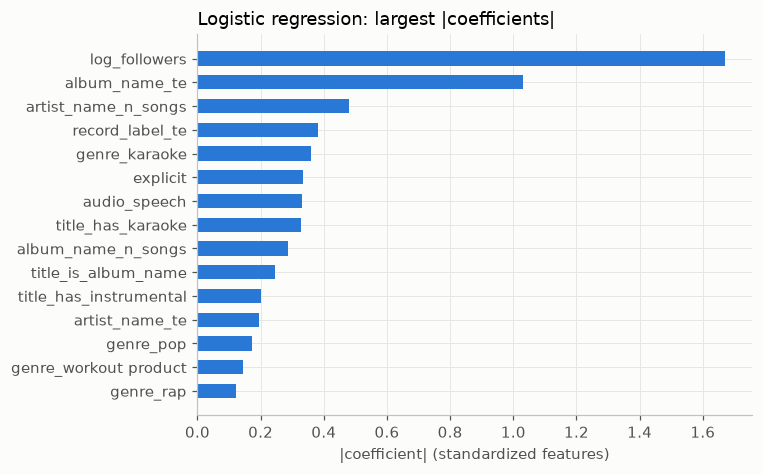

In [4]:
def plot_top_features(values, title, xlabel, n=15):
    """Horizontal bar chart of the n largest values (e.g. feature importances)."""
    top = values.sort_values(ascending=False).head(n)[::-1]  # biggest at the top
    fig, ax = plt.subplots(figsize=(6.5, 4.5))
    ax.barh(top.index, top.values, color=BLUE, height=0.6)
    ax.set_xlabel(xlabel)
    ax.set_title(title, loc="left")
    plt.show()

# feature names after the imputer (it added '*missingindicator*' columns)
names = model[:-1].get_feature_names_out()
coefs = pd.Series(model[-1].coef_[0], index=names)

print("largest positive coefficients (-> more hits):")
print(coefs.sort_values(ascending=False).head(8).round(3).to_string())
print("\nlargest negative coefficients (-> fewer hits):")
print(coefs.sort_values().head(8).round(3).to_string())

plot_top_features(coefs.abs(), "Logistic regression: largest |coefficients|", "|coefficient| (standardized features)")

**Interpretation.** The target encodings and the follower count carry most of the weight, as the single-feature
analysis suggested. Logistic regression can only add up effects linearly. It can't learn rules like
"many followers **and** a pop genre", which is what the tree models are for.

**Careful when reading single coefficients:** `genre_pop` gets a *negative* weight although pop songs are hits 55 % of the time.
That's because each coefficient means "effect **while all other features stay the same**". The pop effect is already
contained in the artist/album hit rates and the follower count, so the extra `genre_pop` column only makes a small correction.
With correlated features, single coefficients can't be read in isolation.

In [5]:
# save predictions for the ensemble (notebook 08)
test_pred = model.predict_proba(log_counts(X_test))[:, 1]
save_predictions("logreg", valid, valid_pred, test, test_pred)